## Preliminaries

Fully train a `ResNet50` on a subset of the Danish Fungi dataset with the hyperparameters found in `ResNet_HPO.ipynb`.

Note: start the Jupyter server from the console within the folder `/mnt/KInsektDaten/teo`.

In [1]:
#import os
#os.chdir('C:\\Users\\Teo\\Documents\\Projects') # equivalent to /teo on server
#os.chdir('../..') # when running code in the server folder from your laptop, you start in the /notebooks folder
#print(os.getcwd())

!pwd
import sys
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import datetime
import glob
from PIL import Image
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, TensorBoard
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from beexplainable.beexplainable.preprocessing import dataset_transformers as dt
from wingbeats import modelling as wm # for building simple classifiers
from wingbeats import processing as wp

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2023-11-21 15:00:40.234986: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-11-21 15:00:40.769718: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 46701 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
#metafolder = './beexplainable/metafiles/Fungi/raw/'
metafolder = './beexplainable/metafiles/Fungi/masked/' # same metainfo for masked and masked_bbox

#FUNGI_PATH = '../data/DanishFungi/DF20M_3spec/'
FUNGI_PATH = '../data/DanishFungi/DF20M_3spec_masked_bbox/'
IMAGES_PATH = metafolder + 'images.txt'
IMAGES_LABELS_PATH = metafolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + 'classes.txt'

PROTOTYPE_PATH = '../data/DanishFungi/Prototypes_3spec/'
MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/'

## Load images

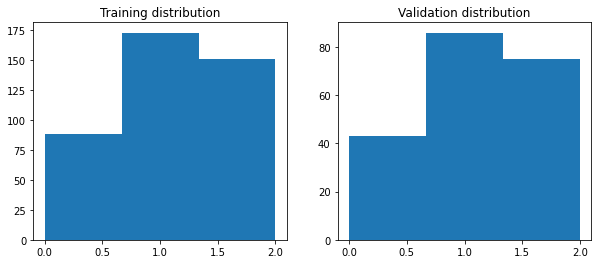

In [5]:
batch_size = 32
img_height = img_width = 224

# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

# Split into training and validation
train_files, val_files, y_train, y_val = train_test_split(file_ids, y_true, test_size = 0.33, random_state = 2022,
                                                          shuffle = True, stratify = y_true)

plt.figure(figsize = (10, 4))
plt.subplot(121)
plt.hist(y_train, bins = len(np.unique(y_train)))
plt.title('Training distribution')

plt.subplot(122)
plt.hist(y_val, bins = len(np.unique(y_val)))
plt.title('Validation distribution')
plt.show()

In [6]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, FUNGI_PATH),
                                          label)

2023-11-21 15:00:40.970194: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46701 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [7]:
# Conversion to tf.Dataset
train_set = ps.parse_to_dataset(train_files, y_train, parse_image_lab)

# Augmentation: flips, rotation, contrast and brightness
augment = True
if augment:
    train_set = dt.augment_dataset(train_set)
train_set = train_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

val_set = ps.parse_to_dataset(val_files, y_val, parse_image_lab)
val_set = val_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
train_set = train_set.map(lambda x, y: (normalization_layer(x), y))
val_set   = val_set.map(lambda x, y: (normalization_layer(x), y))

2023-11-21 15:00:42.505999: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


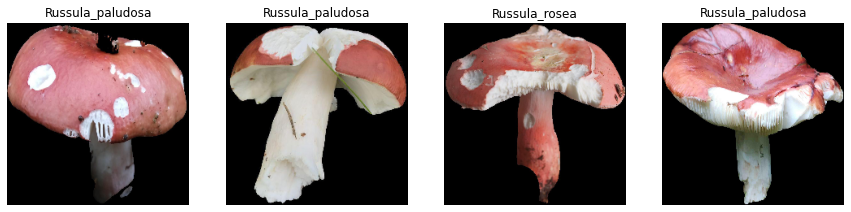

In [8]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(4, batch_size)
with tf.device('/CPU:0'):
    for images, labels in train_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

In [9]:
for image_batch, labels_batch in train_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(32, 224, 224, 3)
tf.Tensor(1, shape=(), dtype=uint8)


2023-11-21 15:00:43.365701: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


## Training

In [17]:
# Define initial training and other model parameters
epochs, drop_rate = 30, 0.5
lr, reg = 1e-4, 1e-4 # less overfitting with 1e-4, but higher val_acc with 1e-3
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'masked_bbox' # raw, masked, bbox, masked_bbox
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form + '_Fungi_4'
print(model_name)
save_weights_file = MODELS_PATH + 'all/Fungi/' + model_name + '/' + model_name + '.h5' # where to save new weights

# Logs directory for TensorBoard
logs_dir = MODELS_PATH + 'all/Fungi/' + model_name + '/logs/'

# History folder
history_dir = MODELS_PATH + 'all/Fungi/' + model_name + '/histories/'

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

ResNet50_iNat_masked_bbox_Fungi_4


In [18]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)
#model.load_weights(save_weights_file)
model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

# Callbacks
checkPoint = ModelCheckpoint(filepath = save_weights_file, save_best_only = True,  monitor = 'val_accuracy', verbose = 1)
earlyStopper = EarlyStopping(monitor = 'val_accuracy', min_delta = 1e-2, patience = 3, verbose = 1)
lr_sched = ReduceLROnPlateau(monitor = 'val_accuracy', factor = 0.1, min_delta = 1e-1, min_lr = lr * 0.01,
                             patience = 2, verbose = 1)
tensorBoard = TensorBoard(log_dir = logs_dir + datetime.datetime.now().strftime("%Y%m%d-%H%M%S"),
                          histogram_freq = 1, write_graph = True, write_images = True)
model_callbacks = [checkPoint, earlyStopper, lr_sched, tensorBoard]

### Raw

In [12]:
# All iNat augmented unfrozen 3 specs, 1e-3
history = model.fit(train_set, epochs = epochs,
                    validation_data = val_set, callbacks = model_callbacks)

Epoch 1/30


2023-11-07 11:02:07.737137: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2023-11-07 11:02:08.241334: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-07 11:02:08.242553: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-07 11:02:08.242592: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2023-11-07 11:02:08.243878: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-07 11:02:08.243978: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


84/84 [==============================] - ETA: 0s - loss: 69.9800 - accuracy: 0.8214 - top_3_accuracy: 1.0000
Epoch 1: val_accuracy improved from -inf to 0.77928, saving model to ./beexplainable/models/all/Fungi/ResNet50_iNat_raw_Fungi/ResNet50_iNat_raw_Fungi.h5
84/84 [==============================] - 120s 1s/step - loss: 69.9800 - accuracy: 0.8214 - top_3_accuracy: 1.0000 - val_loss: 61.5751 - val_accuracy: 0.7793 - val_top_3_accuracy: 1.0000 - lr: 0.0010
Epoch 2/30
84/84 [==============================] - ETA: 0s - loss: 53.5881 - accuracy: 0.9993 - top_3_accuracy: 1.0000
Epoch 2: val_accuracy improved from 0.77928 to 0.78829, saving model to ./beexplainable/models/all/Fungi/ResNet50_iNat_raw_Fungi/ResNet50_iNat_raw_Fungi.h5
84/84 [==============================] - 18s 217ms/step - loss: 53.5881 - accuracy: 0.9993 - top_3_accuracy: 1.0000 - val_loss: 47.3300 - val_accuracy: 0.7883 - val_top_3_accuracy: 1.0000 - lr: 0.0010
Epoch 3/30
84/84 [==============================] - ETA: 0s - 

In [13]:
# Save history
with open(history_dir + model_name + '.pickle', 'wb') as f:
    pickle.dump(history.history, f)

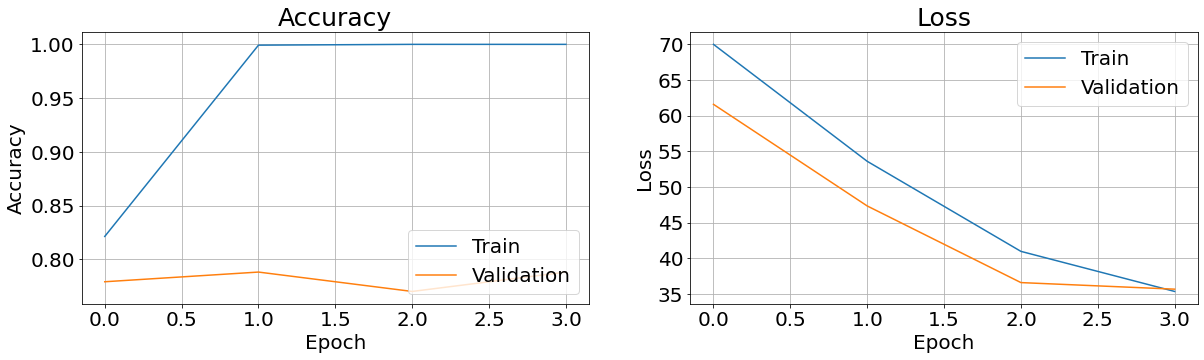

In [20]:
# All iNat augmented unfrozen 3 specs, 1e-4
history = model.fit(train_set, epochs = epochs,
                    validation_data = val_set, callbacks = model_callbacks)

Epoch 1/30
84/84 [==============================] - ETA: 0s - loss: 78.7553 - accuracy: 0.5327 - top_3_accuracy: 1.0000
Epoch 1: val_accuracy improved from -inf to 0.66667, saving model to ./beexplainable/models/all/Fungi/ResNet50_iNat_raw_Fungi_4/ResNet50_iNat_raw_Fungi_4.h5
84/84 [==============================] - 22s 228ms/step - loss: 78.7553 - accuracy: 0.5327 - top_3_accuracy: 1.0000 - val_loss: 77.5829 - val_accuracy: 0.6667 - val_top_3_accuracy: 1.0000 - lr: 1.0000e-04
Epoch 2/30
84/84 [==============================] - ETA: 0s - loss: 76.4564 - accuracy: 0.7374 - top_3_accuracy: 1.0000
Epoch 2: val_accuracy improved from 0.66667 to 0.70270, saving model to ./beexplainable/models/all/Fungi/ResNet50_iNat_raw_Fungi_4/ResNet50_iNat_raw_Fungi_4.h5
84/84 [==============================] - 18s 217ms/step - loss: 76.4564 - accuracy: 0.7374 - top_3_accuracy: 1.0000 - val_loss: 75.4414 - val_accuracy: 0.7027 - val_top_3_accuracy: 1.0000 - lr: 1.0000e-04
Epoch 3/30
84/84 [===============

In [24]:
# Save history
with open(history_dir + model_name + '.pickle', 'wb') as f:
    pickle.dump(history.history, f)

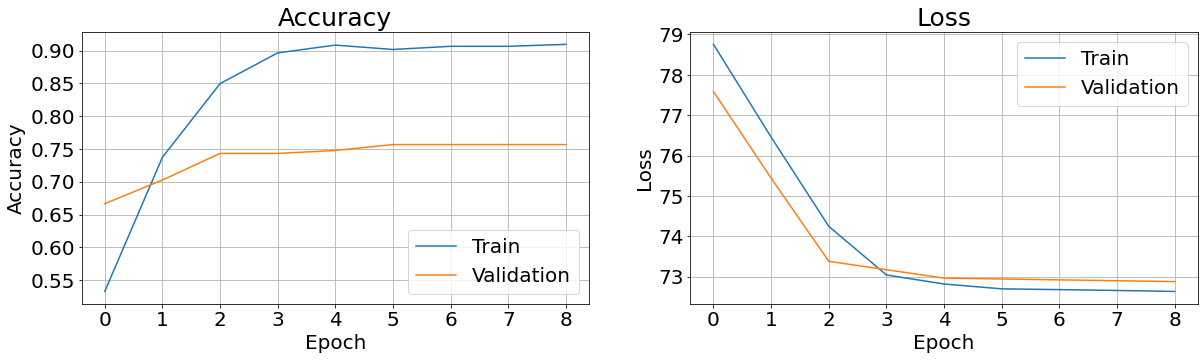

### Masked

In [13]:
# All iNat augmented unfrozen 3 specs, 1e-3
history = model.fit(train_set, epochs = epochs,
                    validation_data = val_set, callbacks = model_callbacks)

Epoch 1/30


2023-11-21 14:32:34.525881: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2023-11-21 14:32:35.044064: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-21 14:32:35.045240: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-21 14:32:35.045293: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2023-11-21 14:32:35.047199: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-21 14:32:35.047301: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


78/78 [==============================] - ETA: 0s - loss: 71.2577 - accuracy: 0.6934 - top_3_accuracy: 1.0000
Epoch 1: val_accuracy improved from -inf to 0.70588, saving model to ./beexplainable/models/all/Fungi/ResNet50_iNat_masked_Fungi/ResNet50_iNat_masked_Fungi.h5
78/78 [==============================] - 89s 1s/step - loss: 71.2577 - accuracy: 0.6934 - top_3_accuracy: 1.0000 - val_loss: 64.0032 - val_accuracy: 0.7059 - val_top_3_accuracy: 1.0000 - lr: 0.0010
Epoch 2/30
78/78 [==============================] - ETA: 0s - loss: 57.4547 - accuracy: 0.9794 - top_3_accuracy: 1.0000
Epoch 2: val_accuracy did not improve from 0.70588
78/78 [==============================] - 14s 184ms/step - loss: 57.4547 - accuracy: 0.9794 - top_3_accuracy: 1.0000 - val_loss: 52.9944 - val_accuracy: 0.6716 - val_top_3_accuracy: 1.0000 - lr: 0.0010
Epoch 3/30
77/78 [============================>.] - ETA: 0s - loss: 48.1423 - accuracy: 0.9602 - top_3_accuracy: 1.0000
Epoch 3: val_accuracy did not improve from

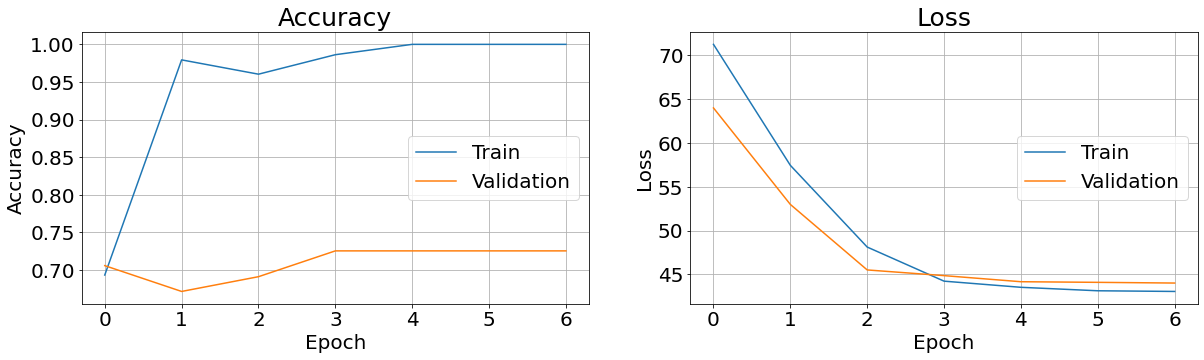

### Masked_bbox

In [12]:
# All iNat augmented unfrozen 3 specs, 1e-3
history = model.fit(train_set, epochs = epochs,
                    validation_data = val_set, callbacks = model_callbacks)

Epoch 1/30


2023-11-21 15:02:50.553988: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2023-11-21 15:02:51.068206: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-21 15:02:51.068946: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-21 15:02:51.068971: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2023-11-21 15:02:51.069684: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-21 15:02:51.082871: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


78/78 [==============================] - ETA: 0s - loss: 71.2807 - accuracy: 0.7342 - top_3_accuracy: 1.0000
Epoch 1: val_accuracy improved from -inf to 0.69608, saving model to ./beexplainable/models/all/Fungi/ResNet50_iNat_masked_bbox_Fungi/ResNet50_iNat_masked_bbox_Fungi.h5
78/78 [==============================] - 59s 669ms/step - loss: 71.2807 - accuracy: 0.7342 - top_3_accuracy: 1.0000 - val_loss: 63.9163 - val_accuracy: 0.6961 - val_top_3_accuracy: 1.0000 - lr: 0.0010
Epoch 2/30
78/78 [==============================] - ETA: 0s - loss: 56.6852 - accuracy: 0.9927 - top_3_accuracy: 1.0000
Epoch 2: val_accuracy improved from 0.69608 to 0.73529, saving model to ./beexplainable/models/all/Fungi/ResNet50_iNat_masked_bbox_Fungi/ResNet50_iNat_masked_bbox_Fungi.h5
78/78 [==============================] - 17s 224ms/step - loss: 56.6852 - accuracy: 0.9927 - top_3_accuracy: 1.0000 - val_loss: 51.2175 - val_accuracy: 0.7353 - val_top_3_accuracy: 1.0000 - lr: 0.0010
Epoch 3/30
77/78 [==========

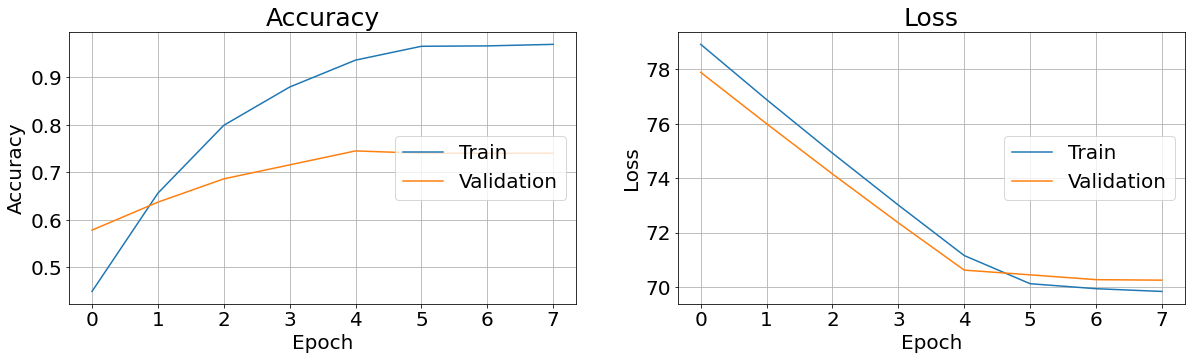

In [20]:
title_size, label_size = 25, 20
fig = plt.figure(figsize = (20, 5))
hist = history.history

plt.subplot(121)
plt.plot(hist['accuracy'])
plt.plot(hist['val_accuracy'])
plt.title('Accuracy', fontsize = title_size)
plt.ylabel('Accuracy', fontsize = label_size)
plt.xlabel('Epoch', fontsize = label_size)
plt.xticks(fontsize = label_size)
plt.yticks(fontsize = label_size)
plt.legend(['Train', 'Validation'], loc = 'center right', fontsize = label_size)
plt.grid()

plt.subplot(122)
plt.plot(hist['loss'])
plt.plot(hist['val_loss'])
plt.title('Loss', fontsize = title_size)
plt.ylabel('Loss', fontsize = label_size)
plt.xlabel('Epoch', fontsize = label_size)
plt.xticks(fontsize = label_size)
plt.yticks(fontsize = label_size)
plt.legend(['Train', 'Validation'], loc = 'center right', fontsize = label_size)
plt.grid()

fig.savefig(FIGURES_PATH + model_name + '_loss_accuracy.png', bbox_inches = 'tight')
plt.show()

### Confusion Matrices

In [21]:
# Build the confusion matrix
y_pred = model.predict(val_set, verbose = 1)
pred_specs = np.argmax(y_pred, axis = 1)
conf_mat = np.round( confusion_matrix(y_val, pred_specs, normalize = 'true'), 2 )

7/7 [==============================] - 1s 34ms/step


In [22]:
# Sort classes alphabetically
sorted_cls = sorted(list(cls_dict.values()))
# Get cls indexes of the sorted classes
sorted_ids = np.argsort(list(cls_dict.values()))
# Permute rows and columns in conf. mat. so that species are sorted
conf_mat = conf_mat[sorted_ids, :]
conf_mat = conf_mat[:, sorted_ids]
# Sort files of prototypes
proto_files = sorted( glob.glob(PROTOTYPE_PATH + '*.JPG') )
# Derive species names
species = [ pf[pf.rfind('/') + 1:] for pf in proto_files]
species = [ s.split('_')[0] + ' ' + s.split('_')[1].split('.JPG')[0] for s in species]
# Read and resize prototype images
proto_imgs = [Image.open(pf).resize((img_width, img_height)) for pf in proto_files]

/tmp/ipykernel_4182032/170383213.py:20: UserWarning: tight_layout not applied: number of rows in subplot specifications must be multiples of one another.
  plt.tight_layout()


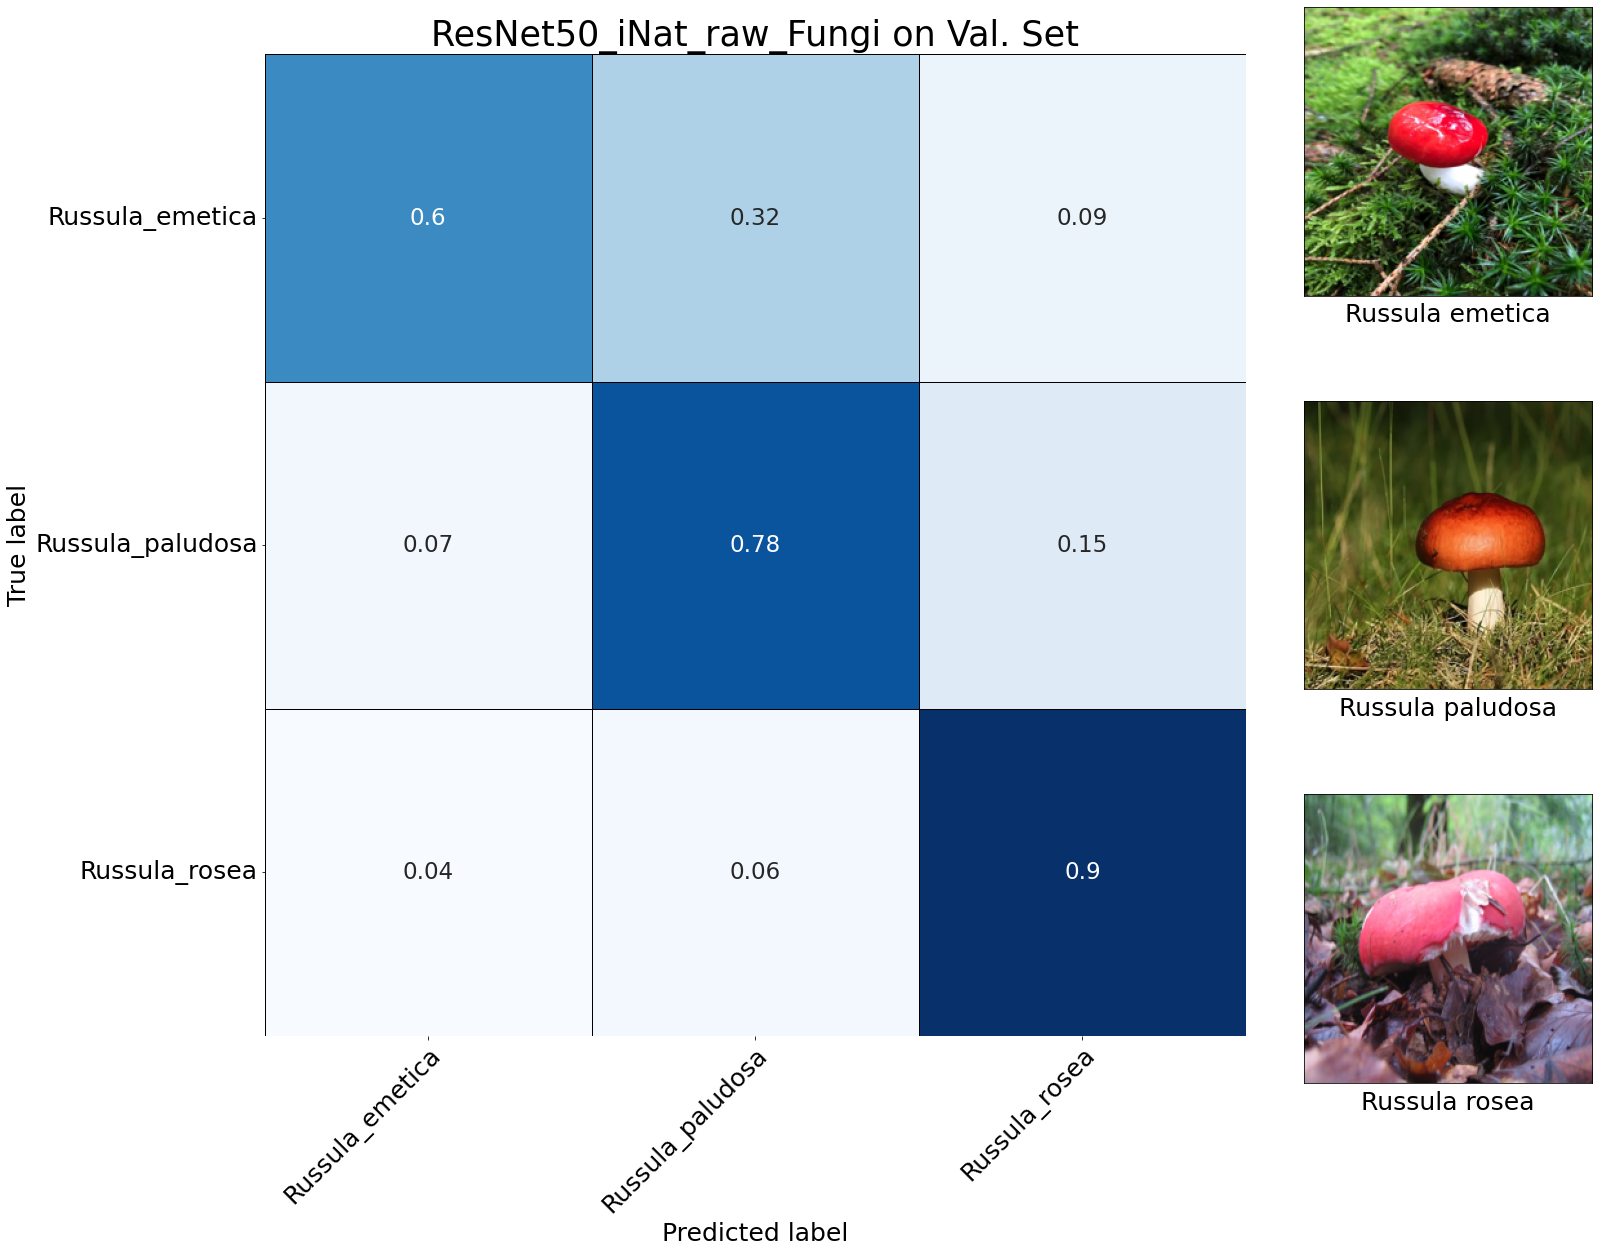

In [67]:
# Plot conf. mat. along with prototypes
num_cls = len(classes)
num_rows, num_cols = num_cls, 5
plt.figure(figsize=(30,35))
plt.subplot2grid((num_rows, num_cols), (0, 0), rowspan = num_rows, colspan = num_cols - 2)
title = model_name + ' on Val. Set'

wp.plot_heatmap(conf_mat, xticklab = sorted_cls, yticklab = sorted_cls,
                xlab = 'Predicted label', ylab = 'True label', title = title,
                path_to_save = None, title_size = 35, ticks_size = 25, label_size = 25, item_size = 23)

for i in range(num_cls):

    plt.subplot2grid((num_rows+2, num_cols), (i+1, num_cols - 2))
    plt.imshow(proto_imgs[i])
    plt.xticks([], []); plt.yticks([], [])
    plt.xlabel(species[i], fontsize = 25)

plt.savefig(FIGURES_PATH + 'conf_mat/' + model_name + '_confmat_val.png', bbox_inches='tight')
plt.tight_layout()
plt.show()

/tmp/ipykernel_4182032/2963208775.py:20: UserWarning: tight_layout not applied: number of rows in subplot specifications must be multiples of one another.
  plt.tight_layout()


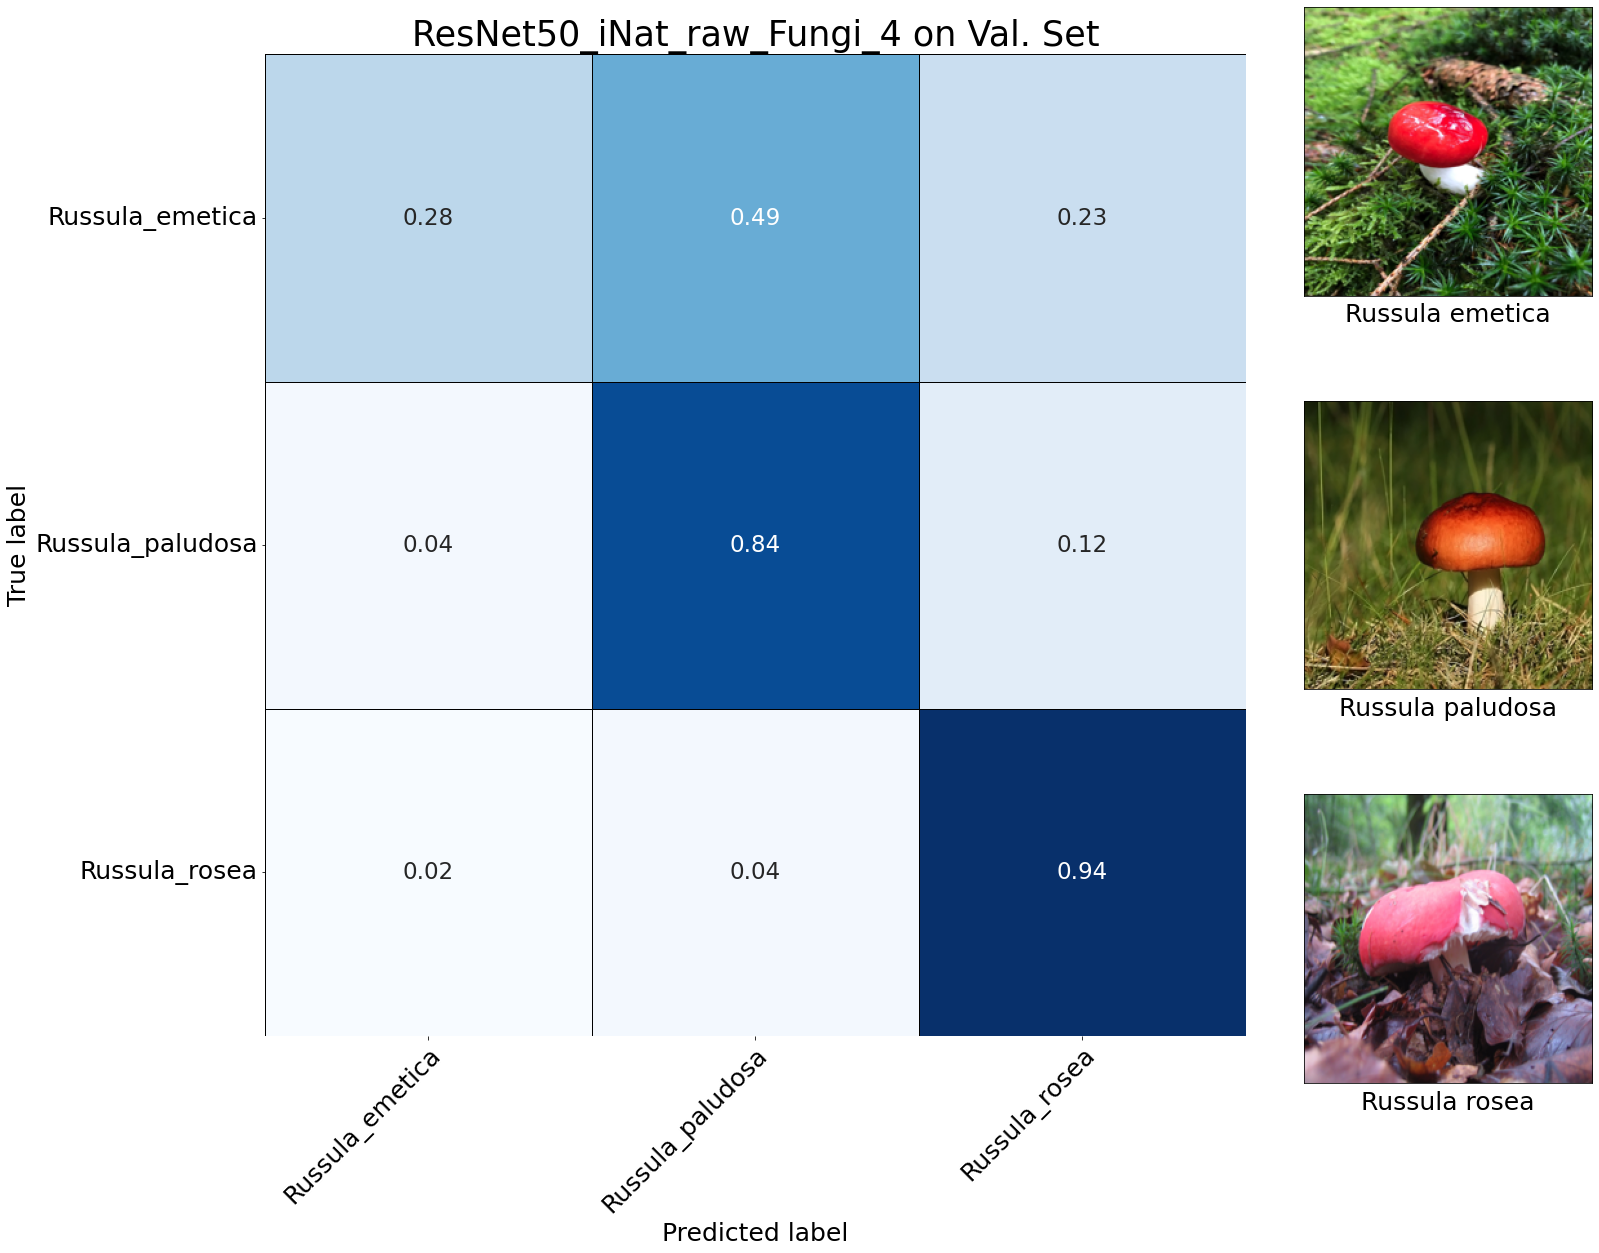

In [57]:
# Plot conf. mat. along with prototypes
num_cls = len(classes)
num_rows, num_cols = num_cls, 5
plt.figure(figsize=(30,35))
plt.subplot2grid((num_rows, num_cols), (0, 0), rowspan = num_rows, colspan = num_cols - 2)
title = model_name + ' on Val. Set'

wp.plot_heatmap(conf_mat, xticklab = sorted_cls, yticklab = sorted_cls,
                xlab = 'Predicted label', ylab = 'True label', title = title,
                path_to_save = None, title_size = 35, ticks_size = 25, label_size = 25, item_size = 23)

for i in range(num_cls):

    plt.subplot2grid((num_rows+2, num_cols), (i+1, num_cols - 2))
    plt.imshow(proto_imgs[i])
    plt.xticks([], []); plt.yticks([], [])
    plt.xlabel(species[i], fontsize = 25)

#plt.savefig(FIGURES_PATH + 'conf_mat/' + model_name + '_confmat_val.png', bbox_inches='tight')
plt.tight_layout()
plt.show()

/tmp/ipykernel_950195/2073676802.py:20: UserWarning: tight_layout not applied: number of rows in subplot specifications must be multiples of one another.
  plt.tight_layout()


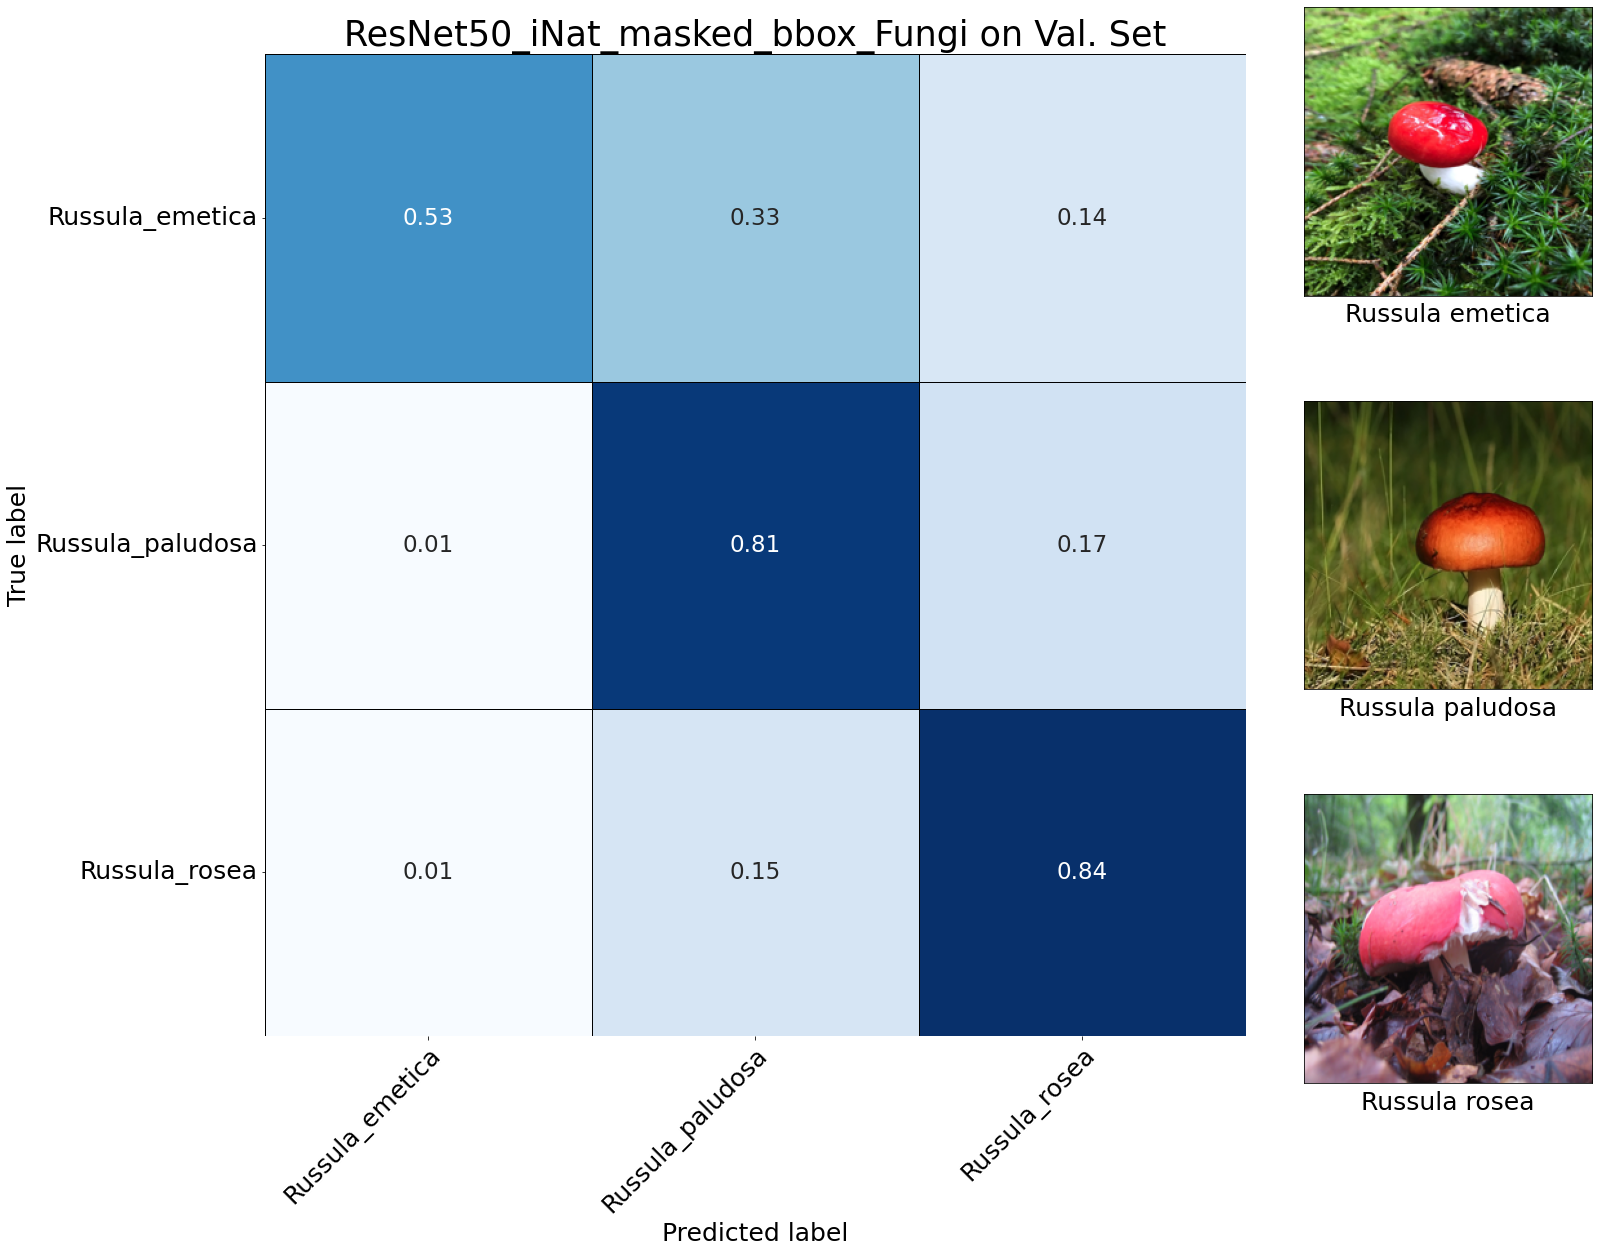

In [16]:
# Plot conf. mat. along with prototypes
num_cls = len(classes)
num_rows, num_cols = num_cls, 5
plt.figure(figsize=(30,35))
plt.subplot2grid((num_rows, num_cols), (0, 0), rowspan = num_rows, colspan = num_cols - 2)
title = model_name + ' on Val. Set'

wp.plot_heatmap(conf_mat, xticklab = sorted_cls, yticklab = sorted_cls,
                xlab = 'Predicted label', ylab = 'True label', title = title,
                path_to_save = None, title_size = 35, ticks_size = 25, label_size = 25, item_size = 23)

for i in range(num_cls):

    plt.subplot2grid((num_rows+2, num_cols), (i+1, num_cols - 2))
    plt.imshow(proto_imgs[i])
    plt.xticks([], []); plt.yticks([], [])
    plt.xlabel(species[i], fontsize = 25)

plt.savefig(FIGURES_PATH + 'conf_mat/' + model_name + '_confmat_val.png', bbox_inches='tight')
plt.tight_layout()
plt.show()

/tmp/ipykernel_950195/2073676802.py:20: UserWarning: tight_layout not applied: number of rows in subplot specifications must be multiples of one another.
  plt.tight_layout()


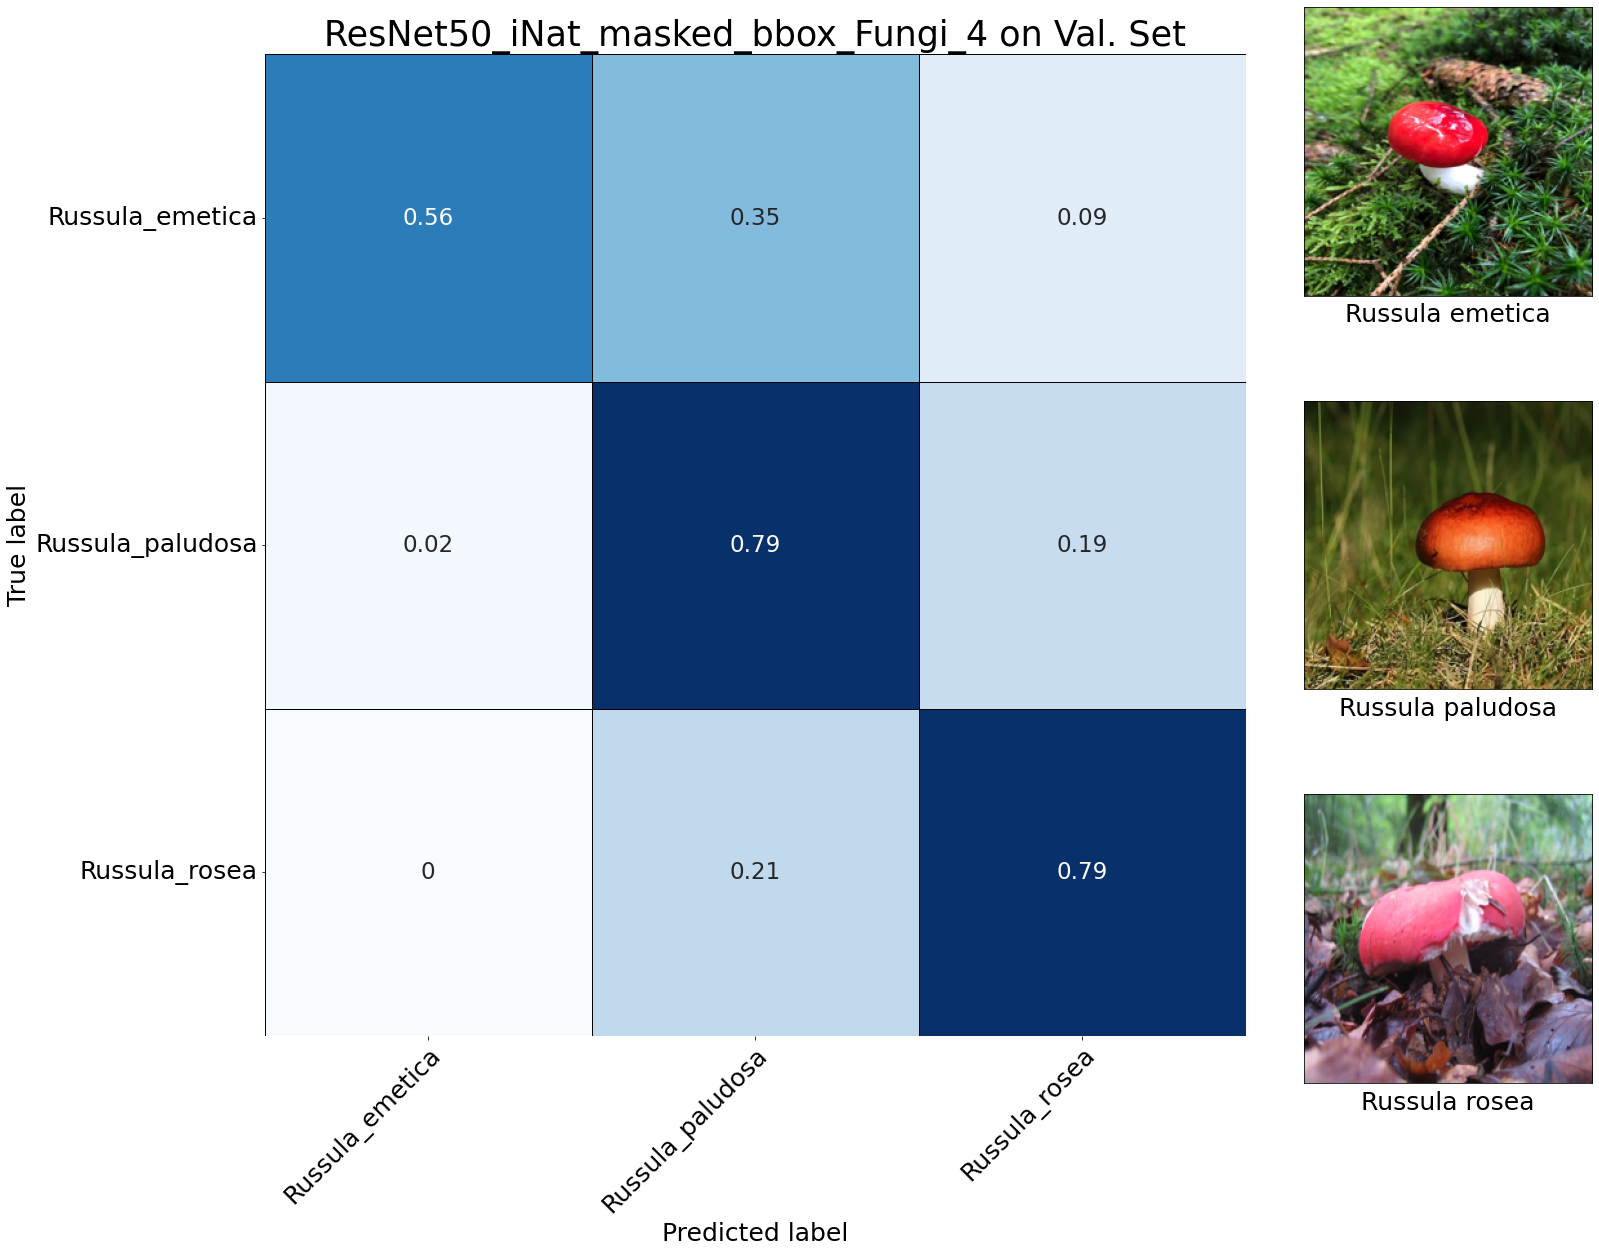

In [23]:
# Plot conf. mat. along with prototypes
num_cls = len(classes)
num_rows, num_cols = num_cls, 5
plt.figure(figsize=(30,35))
plt.subplot2grid((num_rows, num_cols), (0, 0), rowspan = num_rows, colspan = num_cols - 2)
title = model_name + ' on Val. Set'

wp.plot_heatmap(conf_mat, xticklab = sorted_cls, yticklab = sorted_cls,
                xlab = 'Predicted label', ylab = 'True label', title = title,
                path_to_save = None, title_size = 35, ticks_size = 25, label_size = 25, item_size = 23)

for i in range(num_cls):

    plt.subplot2grid((num_rows+2, num_cols), (i+1, num_cols - 2))
    plt.imshow(proto_imgs[i])
    plt.xticks([], []); plt.yticks([], [])
    plt.xlabel(species[i], fontsize = 25)

plt.savefig(FIGURES_PATH + 'conf_mat/' + model_name + '_confmat_val.png', bbox_inches='tight')
plt.tight_layout()
plt.show()